In [3]:
%pip install shapiq
import shapiq
from probly.method import ensemble
from probly.representer import representer
from probly.quantification import quantify

Note: you may need to restart the kernel to use updated packages.


In [45]:
from sklearn.datasets import make_moons
import torch
import numpy as np

X, y = make_moons(n_samples=500, noise=0.1, random_state=0)

print(len(X))   
print(len(y))
Xt = torch.from_numpy(X).float()
yt = torch.from_numpy(y).long()
MERKMALE = ["x1", "x2"]

500
500


In [46]:
import torch.nn as nn
from probly.method import dropout, ensemble


n_features = Xt.shape[1]
n_classes = len(set(y))
net = nn.Sequential(
    nn.Linear(n_features, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, n_classes),   # gibt Logits aus, kein Softmax
)
ens = ensemble(net, num_members=5, predictor_type="logit_classifier")
for i, member in enumerate(ens):
    ...                    # jedes Netz 500-mal trainieren
rep = representer(ens)

In [47]:
def epistemische_unsicherheit(x_np):
    with torch.no_grad():
        x_t = torch.from_numpy(np.asarray(x_np, dtype=np.float32))
        return quantify(rep.represent(x_t)).epistemic.numpy()

In [48]:
punkte = {
    "A: mitten im blauen Mond": np.array([-0.8, 0.6]),
    "B: Grenze zwischen Monden": np.array([0.5, 0.25]),
    "C: weit weg (OOD)":        np.array([3.0, 3.0]),
}

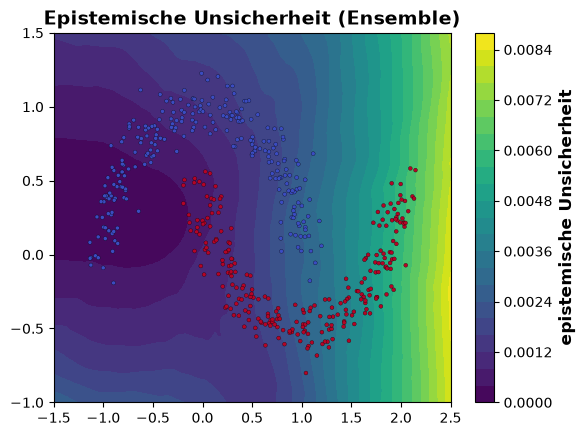

In [49]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from probly.representer import representer
from probly.quantification import quantify

# 1. Gitter über die Ebene: 200 x 200 Punkte
xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 200), np.linspace(-1, 1.5, 200))

# 2. In eine Liste von (x, y)-Punkten umformen, als Torch-Tensor (das Netz braucht Tensoren)
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

# 3. Jedes Ensemble-Mitglied sagt jeden Gitterpunkt vorher, dann wird die Unsicherheit berechnet
eu_grid = quantify(representer(ens).represent(grid)).epistemic.detach()

# 4. Zurück in Gitterform bringen und zeichnen
plt.contourf(xx, yy, eu_grid.reshape(xx.shape), levels=20, cmap="viridis")
plt.colorbar(label="epistemische Unsicherheit")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=8, edgecolors="k", linewidths=0.2)
plt.title("Epistemische Unsicherheit (Ensemble)")
plt.show()



In [52]:
import shapiq

MERKMALE = ["x", "y"]

def funktion(daten):                                   # NumPy rein …
    t = torch.tensor(daten, dtype=torch.float32)       # … für das Netz zu Torch
    eu = quantify(representer(ens).represent(t)).epistemic # … Unsicherheit berechnen
    return eu.detach().numpy()                         # … NumPy raus, eine Zahl pro Punkt

punkt = punkte["C: weit weg (OOD)"]

explainer = shapiq.TabularExplainer(
    model=funktion,
    data=X,
    index="k-SII",
    max_order=2,
    sample_size=None,
)
erklaerung = explainer.explain(punkt, budget=2 ** len(MERKMALE))
print(erklaerung)


InteractionValues(
    index=k-SII, max_order=2, min_order=0, estimated=False, estimation_budget=4,
    n_players=2, baseline_value=0.002101522870361805,
    Top 10 interactions:
        (0,): 0.008962293203280115
        (1,): 0.003386901178105927
        (): 0.002101522870361805
        (0, 1): -0.0027482383747077614
)
